# PRAKTIKUM 09 — Pengayaan Klasifikasi Teks (TF-IDF + Naive Bayes)

**Tema:** *From Data to Machine Learning*  
**Posisi:** Pengayaan setelah Praktikum 01–04; dapat dilakukan secara mandiri sebelum/sesudah studi kasus tabular.  
**Dataset:** `Dataset_Sentimen_Emosi.csv` (teks tweet dan label `Sentimen`).  
**Estimasi pembelajaran:** 120–150 menit untuk penjelasan/demonstrasi; latihan dapat dilanjutkan mandiri.  
**Level:** Pemula → menengah awal.

> **Fokus baru dari Praktikum 02:** di Praktikum 02, TF-IDF digunakan untuk *melihat representasi fitur*. Pada Praktikum 09, TF-IDF dipasang **dalam pipeline pelatihan**, kemudian dikombinasikan dengan **Multinomial Naive Bayes**, divalidasi, diuji, dan diinterpretasikan. Materi ini **tidak mengulang** pembuatan matriks tabular atau normalisasi numerik dari Modul 03.

**Aturan penggunaan:** ini adalah studi klasifikasi teks dengan label dari data sumber; hasil tidak boleh dianggap sebagai alat otomatis untuk menilai orang, emosi, atau opini di luar domain dataset.

## A. Capaian pembelajaran dan peta kegiatan

Setelah kegiatan ini mahasiswa mampu:

1. Menjelaskan tujuan supervised learning untuk teks (`Tweet` sebagai input, `Sentimen` sebagai target).
2. Memeriksa kualitas label, teks kosong, duplikat, serta **teks identik dengan label berkonflik**.
3. Melakukan train–test split setelah pembersihan, lalu mencegah *information leakage* dengan fitting vectorizer **hanya pada train**.
4. Menjelaskan bagaimana TF-IDF dan MultinomialNB menyusun pipeline klasifikasi.
5. Menginterpretasikan vektor dokumen, vocabulary, baseline, accuracy, macro-F1, dan confusion matrix.
6. Memilih hiperparameter dengan cross-validation pada train tanpa memakai test sebagai data seleksi.
7. Menganalisis prediksi salah, token yang berasosiasi dengan kelas, serta keterbatasan domain.
8. Menguji kalimat baru dan menyimpan pipeline yang dapat digunakan ulang.

**Alur kegiatan:** audit sumber → pembersihan terukur → train/test → TF-IDF → Naive Bayes → baseline dan CV → evaluasi test → diagnosis kesalahan → inference → latihan & jawaban.

## B. Persiapan notebook dan struktur dataset

**Kebutuhan:** Python 3, `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `joblib`, `IPython`.

Notebook dirancang untuk berjalan dari **Kernel → Restart & Run All** menggunakan dataset **asli**. Jika ada perubahan lokasi, letakkan `Dataset_Sentimen_Emosi.csv` di folder `praktikum/data/`.

Struktur paket ZIP:

```text
Praktikum_09_Klasifikasi_Teks/
├── PAKET_WORKSHOP.txt
├── README.md
├── requirements.txt
└── praktikum/
    ├── notebooks/09_Pengayaan_Klasifikasi_Teks_Modul_Final_dan_Jawaban.ipynb
    ├── data/Dataset_Sentimen_Emosi.csv
    └── hasil/   # terisi setelah notebook dijalankan
```

**Catatan dataset:** Sumber memiliki kolom `Tweet`, `Sentimen`, dan `Emosi`. Pada modul ini **hanya `Tweet` sebagai fitur** dan **`Sentimen` sebagai label**. Kolom `Emosi` merupakan anotasi berbeda, tidak digunakan untuk prediksi sentimen ataupun dimasukkan ke `X`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_fscore_support
)

SEED = 42
DATA_REL = Path('praktikum/data/Dataset_Sentimen_Emosi.csv')
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / DATA_REL).is_file()), None)
if ROOT is None:
    raise FileNotFoundError(
        'Dataset_Sentimen_Emosi.csv tidak ditemukan. Ekstrak ZIP paket lengkap dan buka notebook dari folder paket.'
    )
DATA_PATH = ROOT / DATA_REL
HASIL = ROOT / 'praktikum' / 'hasil'
HASIL.mkdir(parents=True, exist_ok=True)
print('Dataset:', DATA_PATH)
print('Folder hasil:', HASIL)
print('Versi pandas:', pd.__version__)

Dataset: /Users/masaboe/Documents/NGAJAR/ngudiWaluyo2026/final_release/Workshop_From_Data_to_ML/praktikum/data/Dataset_Sentimen_Emosi.csv
Folder hasil: /Users/masaboe/Documents/NGAJAR/ngudiWaluyo2026/final_release/Workshop_From_Data_to_ML/praktikum/hasil
Versi pandas: 2.3.1


In [2]:
raw = pd.read_csv(DATA_PATH)
print('Dimensi asli:', raw.shape)
print('Nama kolom:', raw.columns.tolist())
print('Tipe data:')
display(raw.dtypes.to_frame('dtype'))
display(raw.head(5))
assert {'Tweet', 'Sentimen', 'Emosi'}.issubset(raw.columns), 'Kolom sumber tidak sesuai.'

Dimensi asli: (905, 3)
Nama kolom: ['Tweet', 'Sentimen', 'Emosi']
Tipe data:


,dtype
Tweet,object
Sentimen,float64
Emosi,int64


,Tweet,Sentimen,Emosi
0,"emang lemes bgt ya mulut lu, gue yg mau beli-b...",-1.0,-2
1,"Cegah mata rantai Covid-19,mari kita dirumah s...",1.0,1
2,aku mohon yaAllah semoga wabah covid-19 menghi...,1.0,-1
3,Pemprov Papua Naikkan Status Jadi Tanggap Daru...,1.0,1
4,Covid belum nyampe prigen mbak hmm hoax,0.0,-2


### B1. Memahami label dan unit analisis

- **Unit sampel:** satu teks pada kolom `Tweet` (belum tentu satu penulis unik).
- **Fitur:** teks mentah, bukan `Emosi` atau label target.
- **Target:** `Sentimen`, berisi kode `-1`, `0`, `1` dalam sumber. Penamaan makna psikologis setiap kode memerlukan dokumentasi anotasi; modul ini melaporkan **kode kelas**, bukan mengasumsikan seluruh label pasti benar.
- **Ruang masalah:** klasifikasi tiga kelas. Perbedaan dengan kasus tabular ialah `Tweet` perlu diubah menjadi representasi numerik oleh vectorizer.

Jangan memakai `Emosi` sebagai prediktor untuk mengklaim hasil dari **teks saja**. Selain mengubah pertanyaan penelitian, atribut tersebut tidak tersedia pada masukan kalimat baru yang tidak berlabel.

In [3]:
print('Missing value:')
display(raw.isna().sum().to_frame('jumlah_missing'))
print('Distribusi label termasuk NaN:')
display(raw['Sentimen'].value_counts(dropna=False).sort_index().to_frame('jumlah'))
print('Duplikat seluruh baris:', int(raw.duplicated().sum()))
print('Teks unik sebelum normalisasi whitespace:', int(raw['Tweet'].nunique(dropna=True)))

Missing value:


,jumlah_missing
Tweet,0
Sentimen,1
Emosi,0


Distribusi label termasuk NaN:


,jumlah
Sentimen,
-1.0,196
0.0,267
1.0,441
NaN,1


Duplikat seluruh baris: 0
Teks unik sebelum normalisasi whitespace: 905


### B2. Tinjauan dua anotasi dalam sumber: Sentimen ≠ Emosi

Sumber memuat dua kolom label numerik. Menemukan keduanya pada baris yang sama **tidak berarti** keduanya mengukur hal identik. Untuk menjelaskan struktur dataset, kita bisa mengamati tabel silang anotasi. Namun, kita **tidak boleh** menafsirkan hubungan semantik berdasarkan angka saja tanpa dokumentasi skema labeling.

In [4]:
# Pemeriksaan untuk pemahaman sumber, bukan fitur bagi model
tabel_anotasi = pd.crosstab(
    raw['Sentimen'], raw['Emosi'], dropna=False,
    rownames=['Kode Sentimen'], colnames=['Kode Emosi']
)
display(tabel_anotasi)
print('Kode unik Emosi:', sorted(raw['Emosi'].dropna().unique().tolist()))

Kode Emosi,-2,-1,1,2
Kode Sentimen,,,,
-1.0,105,50,31,10
0.0,48,84,107,28
1.0,49,111,162,119
NaN,0,0,1,0


Kode unik Emosi: [-2, -1, 1, 2]


## C. Audit kualitas teks dan aturan pembersihan yang transparan

Langkah pembersihan dibuat **minimal** agar konten asli tetap terjaga:

1. Buang record yang `Tweet` atau `Sentimen`-nya kosong.
2. Hapus **spasi di awal/akhir** tweet, kemudian singkirkan teks yang menjadi kosong.
3. Audit tweet identik yang memiliki lebih dari satu `Sentimen`. Record ambigu tersebut **dikeluarkan**, bukan memilih label sesuka hati.
4. Untuk teks identik yang labelnya konsisten, **simpan satu record saja**, sebelum train/test split.

Kita tidak menghapus tanda baca, emoji, slang, atau stopword secara otomatis. Dalam analisis sentimen, keputusan itu dapat menghilangkan informasi. `TfidfVectorizer` tetap menggunakan tokenisasi dasar; batasannya akan dibahas pada interpretasi.

In [5]:
d = raw.dropna(subset=['Tweet', 'Sentimen']).copy()
d['Tweet'] = d['Tweet'].astype(str).str.strip()
d = d.loc[d['Tweet'].ne('')].copy()

# Audit konflik label per teks identik (setelah menghapus spasi tepi).
jumlah_label_per_teks = d.groupby('Tweet')['Sentimen'].nunique()
teks_konflik = jumlah_label_per_teks[jumlah_label_per_teks > 1].index
n_konflik_baris = int(d['Tweet'].isin(teks_konflik).sum())
sebelum_deduplikasi = len(d) - n_konflik_baris

clean = (d.loc[~d['Tweet'].isin(teks_konflik)]
           .drop_duplicates(subset=['Tweet'])
           .copy().reset_index(drop=True))
clean['Sentimen'] = clean['Sentimen'].astype(int)

ringkasan_audit = pd.DataFrame({
    'Tahap': ['Data asli', 'Setelah buang missing/blank',
              'Setelah buang tweet konflik', 'Setelah deduplikasi konsisten'],
    'Jumlah record': [len(raw), len(d), sebelum_deduplikasi, len(clean)]
})
display(ringkasan_audit)
print('Teks berlabel konflik:', len(teks_konflik), '| baris konflik:', n_konflik_baris)
print('Label akhir:', sorted(clean['Sentimen'].unique()))
assert not clean['Tweet'].duplicated().any()
assert set(clean['Sentimen'].unique()) == {-1, 0, 1}

,Tahap,Jumlah record
0,Data asli,905
1,Setelah buang missing/blank,904
2,Setelah buang tweet konflik,902
3,Setelah deduplikasi konsisten,896


Teks berlabel konflik: 1 | baris konflik: 2
Label akhir: [np.int64(-1), np.int64(0), np.int64(1)]


### C1. Kenapa membuang konflik dan duplikat **sebelum split**?

Jika teks yang sama hadir dalam train dan test, metrik evaluasi dapat menjadi terlalu optimistis karena model menguji teks yang pernah dilihat. Jika satu teks memiliki label berlawanan, target evaluasi juga menjadi ambigu.

Di sini kita memilih aturan yang sederhana dan mudah diaudit. Pada studi nyata, duplikat *near-duplicate* (parafrase, retweet, templat) dan informasi pengarang/waktu juga perlu diperiksa, tetapi metadata tersebut tidak disediakan dalam notebook sumber.

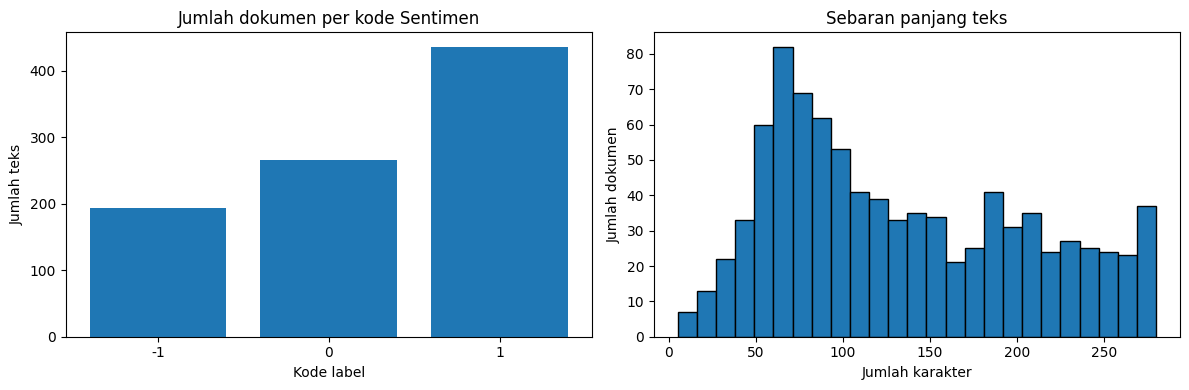

Statistik panjang karakter:


,panjang_karakter
count,896.0
mean,132.8
std,72.3
min,5.0
25%,72.0
50%,115.5
75%,193.0
max,280.0


Statistik jumlah token berdasarkan split spasi (indikasi kasar):


,perkiraan_token
count,896.0
mean,19.8
std,10.9
min,1.0
25%,11.0
50%,17.0
75%,28.0
max,49.0


In [6]:
label_counts = clean['Sentimen'].value_counts().sort_index()
lengths = clean['Tweet'].str.len()
words = clean['Tweet'].str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(label_counts.index.astype(str), label_counts.to_numpy())
axes[0].set(title='Jumlah dokumen per kode Sentimen', xlabel='Kode label', ylabel='Jumlah teks')
axes[1].hist(lengths, bins=25, edgecolor='black')
axes[1].set(title='Sebaran panjang teks', xlabel='Jumlah karakter', ylabel='Jumlah dokumen')
fig.tight_layout()
plt.show()
print('Statistik panjang karakter:')
display(lengths.describe().round(1).to_frame('panjang_karakter'))
print('Statistik jumlah token berdasarkan split spasi (indikasi kasar):')
display(words.describe().round(1).to_frame('perkiraan_token'))

### C2. Persentase record yang disisihkan

Audit yang baik tidak sekadar menyebut `dropna()`. Sebutkan *berapa banyak* data yang hilang akibat masing-masing aturan dan jangan mengklaim semua record terhapus adalah kesalahan input. Satu teks berlabel konflik bisa menunjukkan persoalan definisi anotasi yang membutuhkan adjudikasi.

In [7]:
ringkasan_tahap = ringkasan_audit.copy()
ringkasan_tahap['Tersisih_kumulatif'] = len(raw) - ringkasan_tahap['Jumlah record']
ringkasan_tahap['Tersisih_persen'] = (
    100 * ringkasan_tahap['Tersisih_kumulatif'] / len(raw)
).round(2)
display(ringkasan_tahap)

,Tahap,Jumlah record,Tersisih_kumulatif,Tersisih_persen
0,Data asli,905,0,0.00
1,Setelah buang missing/blank,904,1,0.11
2,Setelah buang tweet konflik,902,3,0.33
3,Setelah deduplikasi konsisten,896,9,0.99


## D. Pemisahan train/test yang aman

Dataset yang sudah dideduplikasi kita bagi menjadi **75% train dan 25% test**, dengan stratifikasi label. **Test disimpan** untuk evaluasi akhir dan **tidak digunakan** dalam `fit`, pemilihan kata (*vocabulary*), maupun pencarian hiperparameter.

Pendekatan ini mengukur generalisasi terhadap teks yang tidak identik dalam kumpulan data yang sama. Karena sumber merupakan teks bertopik tertentu, ini **bukan bukti generalisasi** ke domain atau waktu lain.

In [8]:
X = clean['Tweet'].copy()
y = clean['Sentimen'].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)
print('Train:', X_train.shape, '| Test:', X_test.shape)
rasio = pd.DataFrame({
    'train_n': y_train.value_counts().sort_index(),
    'test_n': y_test.value_counts().sort_index(),
    'train_proporsi': y_train.value_counts(normalize=True).sort_index(),
    'test_proporsi': y_test.value_counts(normalize=True).sort_index(),
})
display(rasio.round(3))
assert set(X_train.index).isdisjoint(set(X_test.index))
assert set(X_train).isdisjoint(set(X_test))  # tak ada teks identik bocor antar-subset

Train: (672,) | Test: (224,)


,train_n,test_n,train_proporsi,test_proporsi
Sentimen,,,,
-1,145,49,0.216,0.219
0,200,66,0.298,0.295
1,327,109,0.487,0.487


## E. TF-IDF untuk data training — dari teks ke matriks fitur

Pada Praktikum 02 sudah dibahas konsep representasi. Sekarang perhatikan aturan machine learning: fungsi vectorizer harus **belajar vocabulary dan IDF dari `X_train` saja**.

Untuk satu term $t$ dalam dokumen $d$, bobot TF-IDF meningkat seiring kemunculan term dalam dokumen tetapi menurun jika term tersebut umum di banyak dokumen. Implementasi scikit-learn menggunakan formula IDF dan normalisasi yang ditentukan oleh parameternya.

**Parameter demonstrasi:** `max_features=2000` membatasi vocabulary maksimum 2.000 fitur, `ngram_range=(1,1)` memakai unigram, dan `lowercase=True` menyamakan kapitalisasi. Ukuran vocabulary aktual mungkin lebih kecil dari 2.000.

Representasi TF-IDF **bukan** embedding semantik: dua kata berbeda yang maknanya mirip tetap merupakan fitur berbeda, kecuali ditangani secara eksplisit.

In [9]:
vectorizer_demo = TfidfVectorizer(max_features=2000, ngram_range=(1, 1))
Xt_train = vectorizer_demo.fit_transform(X_train)
Xt_test = vectorizer_demo.transform(X_test)  # tanpa fit ulang!
feature_names = vectorizer_demo.get_feature_names_out()
print('Shape train input:', X_train.shape, '→ TF-IDF:', Xt_train.shape)
print('Shape test input :', X_test.shape, '→ TF-IDF:', Xt_test.shape)
print('Jenis matriks:', type(Xt_train).__name__)
print('Jumlah term:', len(feature_names))
print('Non-zero entries train:', Xt_train.nnz)
assert Xt_train.shape[1] == Xt_test.shape[1]
assert np.all(Xt_train.data >= 0)

Shape train input: (672,) → TF-IDF: (672, 2000)
Shape test input : (224,) → TF-IDF: (224, 2000)
Jenis matriks: csr_matrix
Jumlah term: 2000
Non-zero entries train: 10440


### E1. Menampilkan **feature space dari satu dokumen**

`Xt_train[0]` adalah vektor fitur dokumen train pertama, berukuran `(1, jumlah_term)`. Mayoritas bobot akan bernilai nol (*sparse*). Kita hanya menampilkan term dengan bobot nonnol agar mudah dibaca. Ini menjawab pertanyaan pembelajaran utama Modul 02, tetapi kini menggunakan vectorizer yang benar-benar di-fit pada training.

In [10]:
record_idx = 0
satu_teks = X_train.iloc[record_idx]
satu_vektor = Xt_train[record_idx]
term_satu_dokumen = pd.DataFrame({
    'Term': feature_names,
    'TF-IDF': satu_vektor.toarray().ravel()
})
term_satu_dokumen = (term_satu_dokumen.loc[lambda v: v['TF-IDF'] > 0]
                      .sort_values('TF-IDF', ascending=False)
                      .reset_index(drop=True))
print('Teks sampel:', satu_teks)
print('Bentuk vektor:', satu_vektor.shape)
print('Jumlah fitur nonnol:', len(term_satu_dokumen))
display(term_satu_dokumen.head(20))

Teks sampel: Ada 15 cra mnyurh Covid-19 sgr prg 5.Jngn lgi mlas ke Msjd dll. Bkankh Covid-19 tlh mndidk kta, bgaimna sdh & strssnya kta tnpa ada tmpt mmohn,brdoa,tk bsa bribdh brjamah &shalt di Msjd dlm suasna btin yg dmai. Bgaimna sdhnya mlps sdr kta yg mninggl tnpa dishltkn di Msjd?.
Bentuk vektor: (1, 2000)
Jumlah fitur nonnol: 20


,Term,TF-IDF
0,kta,0.495178
1,msjd,0.495178
2,bgaimna,0.330119
3,tnpa,0.330119
4,tmpt,0.165059
5,sdr,0.165059
6,dll,0.155244
7,tlh,0.155244
8,sgr,0.155244
9,ada,0.154648


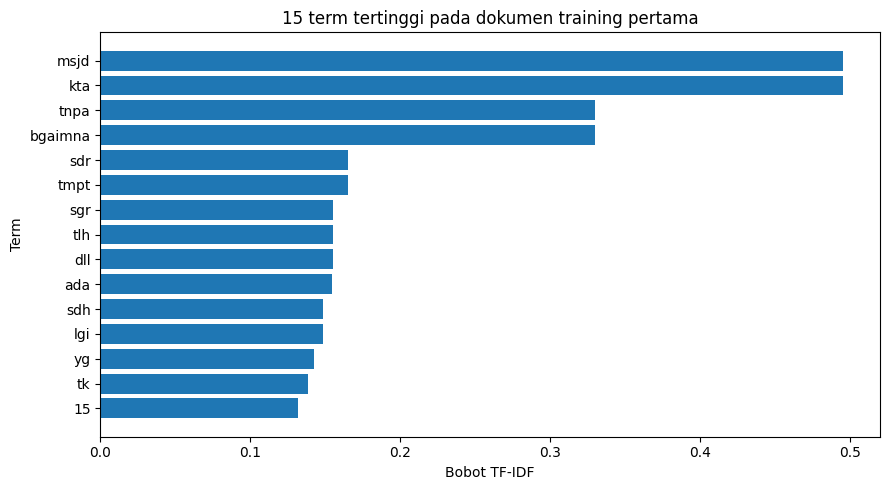

In [11]:
top = term_satu_dokumen.head(15).sort_values('TF-IDF')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top['Term'], top['TF-IDF'])
ax.set(xlabel='Bobot TF-IDF', ylabel='Term',
       title='15 term tertinggi pada dokumen training pertama')
fig.tight_layout()
plt.show()

### E2. Apakah sebuah term tidak terlihat pada dokumen baru?

Jika term pada teks baru tidak ada di vocabulary training, vectorizer akan mengabaikannya. Ini disebut **out-of-vocabulary (OOV)**. Mengubah `max_features`, `min_df`, atau `ngram_range` berpotensi mengubah jumlah term.

**Aturan:** jangan lakukan `fit_transform(X_test)`. Itu membentuk ruang fitur berbeda dan menyebabkan kebocoran informasi dari test, bahkan jika label test tidak dipakai.

In [12]:
contoh_baru = ['pelayanan sehat dan aman', 'zzzztokenunikqqq']
vektor_baru = vectorizer_demo.transform(contoh_baru)
print('Vocabulary pada train:', len(feature_names))
print('Nonzero TF-IDF dua teks baru:', [vektor_baru[i].nnz for i in range(2)])
print('Total bentuk vektor data baru:', vektor_baru.shape)

Vocabulary pada train: 2000
Nonzero TF-IDF dua teks baru: [4, 0]
Total bentuk vektor data baru: (2, 2000)


### E3. Membandingkan beberapa dokumen training di ruang fitur yang sama

Semua dokumen memiliki jumlah kolom yang **identik**, walau tiap dokumen biasanya hanya mengaktifkan sebagian kecil term. Untuk visualisasi, kita pilih 12 term dengan bobot total tertinggi pada **lima dokumen train pertama**; hasil ini bukan analisis kosa kata seluruh populasi.

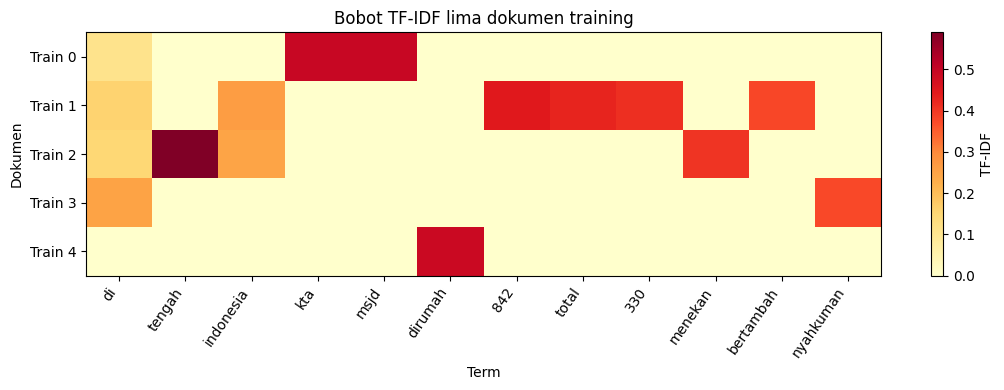

In [13]:
from scipy.sparse import issparse
sample_n = min(5, Xt_train.shape[0])
sub_matriks = Xt_train[:sample_n]
skor_term = np.asarray(sub_matriks.sum(axis=0)).ravel()
indeks_top = np.argsort(skor_term)[-12:][::-1]
fitur_terpilih = feature_names[indeks_top]
v = sub_matriks[:, indeks_top].toarray()
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(v, aspect='auto', interpolation='nearest', cmap='YlOrRd')
ax.set_xticks(range(len(fitur_terpilih)), labels=fitur_terpilih, rotation=55, ha='right')
ax.set_yticks(range(sample_n), labels=[f'Train {i}' for i in range(sample_n)])
ax.set(title='Bobot TF-IDF lima dokumen training', xlabel='Term', ylabel='Dokumen')
fig.colorbar(im, ax=ax, label='TF-IDF')
fig.tight_layout()
plt.show()

## F. Model Multinomial Naive Bayes (MNB)

Naive Bayes memperkirakan suatu kelas berdasarkan frekuensi/berat fitur dan **asumsi independensi bersyarat antarfitur**. Dalam bentuk sederhana:

$$P(c\mid d) \propto P(c) \prod_{t\in V} P(t\mid c)^{w_{t,d}}$$

- $c$ = kode kelas; $P(c)$ = prior kelas.
- $V$ = vocabulary yang dibentuk dari data training.
- $w_{t,d}$ = nilai fitur term (dalam modul ini berupa bobot TF-IDF nonnegatif).

`MultinomialNB` bekerja dengan *counts* nonnegatif dan dalam praktik juga umum dipakai dengan TF-IDF sebagai **pembobotan**, meskipun bobot desimal tidak benar-benar hitungan kejadian diskrit. `alpha` melakukan smoothing agar term yang tidak ditemukan pada suatu kelas tidak langsung menghasilkan probabilitas nol.

Untuk demonstrasi pertama, gunakan `alpha=1.0` dan `max_features=2000` dari notebook sumber.

In [14]:
model_awal = Pipeline(steps=[
    ('tfidf', TfidfVectorizer(max_features=2000)),
    ('model', MultinomialNB(alpha=1.0))
])
model_awal.fit(X_train, y_train)
print('Tahapan pipeline:', list(model_awal.named_steps))
print('Kelas:', model_awal.named_steps['model'].classes_)
print('Jumlah fitur setelah fit:', len(model_awal.named_steps['tfidf'].get_feature_names_out()))
print('Prediksi ilustratif (kode kelas):',
      model_awal.predict(['semoga keadaan membaik', 'sangat mengecewakan']))

Tahapan pipeline: ['tfidf', 'model']
Kelas: [-1  0  1]
Jumlah fitur setelah fit: 2000
Prediksi ilustratif (kode kelas): [1 0]


### F1. Mengapa harus menggunakan `Pipeline`?

Pipeline memastikan bahwa **setiap fold validasi** menerapkan langkah `fit` TF-IDF hanya pada bagian training fold, kemudian `transform` pada fold validasi. Jika vocabulary/IDF di-fit pada seluruh data sebelum cross-validation, skor validasi bisa bias.

Satu model yang disimpan sebagai Pipeline juga menyimpan **vectorizer + classifier** sekaligus; kalimat baru tidak memerlukan pengodean fitur secara manual.

### F2. Eksperimen mini: peran probabilitas prior dan smoothing

Contoh berikut adalah **data ilustratif**, bukan record tambahan dari dataset. Kita bandingkan kelas `0` dan `1` dari empat kalimat mini untuk melihat bahwa `MultinomialNB` belajar jumlah/berat token per kelas. Pada kasus ini digunakan **CountVectorizer** agar hubungan token dan *counts* lebih transparan; model utama tetap TF-IDF.

Rumus smoothing sederhana untuk term $t$ di kelas $c$ adalah

$$P(t\mid c)=\frac{N_{t,c}+\alpha}{N_c+\alpha|V|}.$$

$N_{t,c}$ adalah jumlah kemunculan term $t$ pada kelas $c$; $N_c$ total seluruh term kelas itu; $|V|$ ukuran vocabulary.

In [15]:
teks_toy = ['aman aman sehat', 'aman sehat', 'buruk sakit', 'buruk sekali']
label_toy = [1, 1, 0, 0]
cv_toy = CountVectorizer()
X_toy = cv_toy.fit_transform(teks_toy)
nb_toy = MultinomialNB(alpha=1.0).fit(X_toy, label_toy)
display(pd.DataFrame(X_toy.toarray(), columns=cv_toy.get_feature_names_out(),
                     index=[f'Dokumen {i+1}' for i in range(len(teks_toy))]))
display(pd.DataFrame(np.exp(nb_toy.feature_log_prob_),
                     columns=cv_toy.get_feature_names_out(),
                     index=[f'Kelas {c}' for c in nb_toy.classes_]).round(3))
print('Probabilitas prior kelas:', dict(zip(nb_toy.classes_,
                                          np.exp(nb_toy.class_log_prior_).round(3))))

,aman,buruk,sakit,sehat,sekali
Dokumen 1,2,0,0,1,0
Dokumen 2,1,0,0,1,0
Dokumen 3,0,1,1,0,0
Dokumen 4,0,1,0,0,1


,aman,buruk,sakit,sehat,sekali
Kelas 0,0.111,0.333,0.222,0.111,0.222
Kelas 1,0.400,0.100,0.100,0.300,0.100


Probabilitas prior kelas: {np.int64(0): np.float64(0.5), np.int64(1): np.float64(0.5)}


## G. Membandingkan baseline dan model awal menggunakan cross-validation

Baseline `DummyClassifier(strategy='most_frequent')` menebak label yang paling sering pada training. Model belum layak dianggap berhasil hanya karena accuracy-nya tinggi bila kelas terbesar memang dominan.

Karena terdapat tiga kelas dengan jumlah berbeda, kita gunakan **macro-F1** sebagai metrik pembanding utama: F1 dihitung pada setiap kelas, lalu dirata-ratakan **tanpa bobot berdasarkan frekuensi kelas**. Ini tidak otomatis berarti sama pentingnya secara substantif; hanya membuat kesalahan pada kelas minoritas lebih terlihat.

Semua skor cross-validation berikut dihitung **hanya di train**.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
baseline = DummyClassifier(strategy='most_frequent')
cv_baseline = cross_val_score(baseline, X_train, y_train, cv=cv,
                              scoring='f1_macro', n_jobs=1)
cv_awal = cross_val_score(model_awal, X_train, y_train, cv=cv,
                          scoring='f1_macro', n_jobs=1)
cv_summary = pd.DataFrame({
    'Pendekatan': ['Baseline (kelas mayoritas)', 'TF-IDF + MNB (awal)'],
    'macro-F1_rata2': [cv_baseline.mean(), cv_awal.mean()],
    'macro-F1_std': [cv_baseline.std(), cv_awal.std()]
})
display(cv_summary.round(4))

,Pendekatan,macro-F1_rata2,macro-F1_std
0,Baseline (kelas mayoritas),0.2182,0.0006
1,TF-IDF + MNB (awal),0.3613,0.0129


### G1. Pengayaan: CountVectorizer + MNB vs TF-IDF + MNB

`MultinomialNB` dirancang untuk data counts; TF-IDF adalah bobot alternatif yang sering dipakai dalam klasifikasi teks. Dengan **split CV yang sama dan hanya data train**, kita dapat membandingkan apakah pembobotan TF-IDF memberi manfaat pada corpus ini. Angka berikut tidak boleh dipakai untuk memilih kembali model setelah melihat holdout.

In [17]:
model_counts = Pipeline([
    ('counts', CountVectorizer(max_features=2000)),
    ('model', MultinomialNB(alpha=1.0))
])
cv_counts = cross_val_score(model_counts, X_train, y_train, cv=cv,
                            scoring='f1_macro', n_jobs=1)
display(pd.DataFrame({
    'Representasi': ['Count / Bag of Words', 'TF-IDF'],
    'macro_F1_CV': [cv_counts.mean(), cv_awal.mean()],
    'std_CV': [cv_counts.std(), cv_awal.std()]
}).round(4))

,Representasi,macro_F1_CV,std_CV
0,Count / Bag of Words,0.5171,0.0287
1,TF-IDF,0.3613,0.0129


## H. Pemilihan hiperparameter pada training saja

Parameter yang diteliti:

- `ngram_range`: unigram atau unigram + bigram.
- `min_df`: term harus muncul dalam sedikitnya 1 atau 2 dokumen training.
- `alpha`: tingkat smoothing MultinomialNB (`0.5`, `1.0`, atau `2.0`).

Kita menggunakan `GridSearchCV` dengan **macro-F1**. Semua kombinasi dipilih berdasarkan rata-rata validasi internal. Test tetap disembunyikan hingga Bagian I.

> Hiperparameter terbaik hanya berlaku untuk dataset dan protokol ini. Tidak boleh dilaporkan sebagai bukti pengaturan terbaik secara universal.

In [18]:
search_space = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [1, 2],
    'model__alpha': [0.5, 1.0, 2.0],
}
search = GridSearchCV(
    estimator=Pipeline([
        ('tfidf', TfidfVectorizer(max_features=2000)),
        ('model', MultinomialNB())
    ]),
    param_grid=search_space,
    cv=cv,
    scoring='f1_macro',
    n_jobs=1,
    refit=True,
    return_train_score=False
)
search.fit(X_train, y_train)
print('Kombinasi diuji:', len(search.cv_results_['params']))
print('Hiperparameter terpilih:', search.best_params_)
print('Macro-F1 CV terbaik:', round(float(search.best_score_), 4))
model_final = search.best_estimator_

Kombinasi diuji: 12
Hiperparameter terpilih: {'model__alpha': 0.5, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}
Macro-F1 CV terbaik: 0.4907


Peringkat validasi kombinasi:


,param_tfidf__ngram_range,param_tfidf__min_df,param_model__alpha,mean_test_score,std_test_score,rank_test_score
2,"(1, 1)",2,0.5,0.4907,0.0312,1
3,"(1, 2)",2,0.5,0.4839,0.0354,2
1,"(1, 2)",1,0.5,0.4668,0.0299,3
0,"(1, 1)",1,0.5,0.4441,0.0263,4
6,"(1, 1)",2,1.0,0.4123,0.0273,5
7,"(1, 2)",2,1.0,0.3974,0.0303,6
5,"(1, 2)",1,1.0,0.3969,0.0247,7
4,"(1, 1)",1,1.0,0.3613,0.0129,8
10,"(1, 1)",2,2.0,0.3180,0.0151,9
11,"(1, 2)",2,2.0,0.3152,0.0087,10


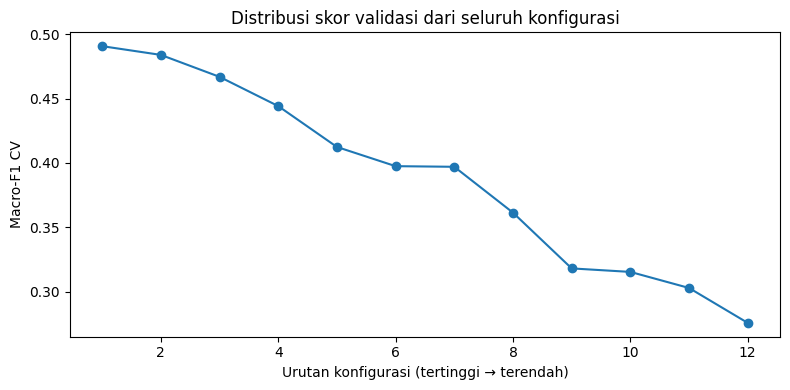

In [19]:
hasil_cv = pd.DataFrame(search.cv_results_)[[
    'param_tfidf__ngram_range', 'param_tfidf__min_df', 'param_model__alpha',
    'mean_test_score', 'std_test_score', 'rank_test_score'
]].sort_values(['rank_test_score', 'mean_test_score'], ascending=[True, False])
print('Peringkat validasi kombinasi:')
display(hasil_cv.head(12).round(4))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(hasil_cv) + 1), hasil_cv['mean_test_score'].to_numpy(), 'o-')
ax.set(xlabel='Urutan konfigurasi (tertinggi → terendah)', ylabel='Macro-F1 CV',
       title='Distribusi skor validasi dari seluruh konfigurasi')
fig.tight_layout()
plt.show()

## I. Evaluasi satu kali pada data holdout test

Model final telah dipilih dari training. Sekarang kita membandingkan tiga pendekatan pada test yang sama:

1. **Baseline**: tebak kelas mayoritas.
2. **Model awal**: TF-IDF (unigram, 2000 fitur) + MNB alpha 1.
3. **Model final**: konfigurasi terbaik menurut CV train.

Metrik: accuracy, balanced accuracy, macro-F1, dan weighted-F1. **Jangan mengubah hyperparameter lagi berdasarkan hasil test ini**; bila ingin mengulangi proses desain model, gunakan validasi tambahan atau holdout baru.

In [20]:
baseline.fit(X_train, y_train)
pred_baseline = baseline.predict(X_test)
pred_awal = model_awal.predict(X_test)
pred_final = model_final.predict(X_test)

def metrik_ringkas(y_true, y_hat, nama):
    return {
        'Model': nama,
        'Accuracy': accuracy_score(y_true, y_hat),
        'Balanced accuracy': balanced_accuracy_score(y_true, y_hat),
        'Macro-F1': f1_score(y_true, y_hat, average='macro', zero_division=0),
        'Weighted-F1': f1_score(y_true, y_hat, average='weighted', zero_division=0),
    }

tabel_metrik = pd.DataFrame([
    metrik_ringkas(y_test, pred_baseline, 'Baseline'),
    metrik_ringkas(y_test, pred_awal, 'TF-IDF + MNB awal'),
    metrik_ringkas(y_test, pred_final, 'TF-IDF + MNB final')
])
display(tabel_metrik.round(4))
print('Classification report final (test):')
print(classification_report(y_test, pred_final, labels=[-1, 0, 1],
                            target_names=['-1', '0', '1'], zero_division=0))

,Model,Accuracy,Balanced accuracy,Macro-F1,Weighted-F1
0,Baseline,0.4866,0.3333,0.2182,0.3186
1,TF-IDF + MNB awal,0.5893,0.4622,0.4428,0.5150
2,TF-IDF + MNB final,0.6250,0.5511,0.5614,0.6015


Classification report final (test):
              precision    recall  f1-score   support

          -1       0.59      0.39      0.47        49
           0       0.62      0.39      0.48        66
           1       0.63      0.87      0.73       109

    accuracy                           0.62       224
   macro avg       0.62      0.55      0.56       224
weighted avg       0.62      0.62      0.60       224



### I1. Cara membaca classification report dan confusion matrix

- **Precision kelas c:** di antara prediksi c, proporsi yang benar-benar berlabel c.
- **Recall kelas c:** di antara record berlabel c, proporsi yang berhasil diprediksi c.
- **F1 kelas c:** rata-rata harmonik precision dan recall kelas c.
- **Support:** jumlah record test dengan label aktual c.
- **Macro-F1:** rerata F1 ketiga kelas tanpa pembobotan frekuensi.
- **Weighted-F1:** rerata F1 berdasarkan support setiap kelas.

**Perhatikan:** nilai kelas `-1`, `0`, dan `1` berasal dari label anotasi. Tidak tepat memberi interpretasi rinci tentang kondisi psikologis penulis berdasarkan satu label otomatis.

,Prediksi -1,Prediksi 0,Prediksi 1
Aktual -1,19,9,21
Aktual 0,6,26,34
Aktual 1,7,7,95


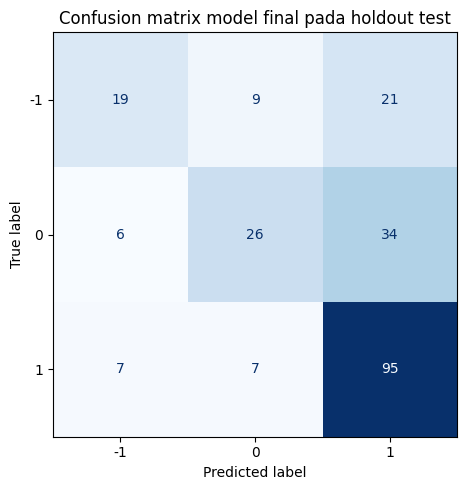

In [21]:
labels = [-1, 0, 1]
cm = confusion_matrix(y_test, pred_final, labels=labels)
display(pd.DataFrame(cm,
                     index=[f'Aktual {c}' for c in labels],
                     columns=[f'Prediksi {c}' for c in labels]))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=[str(c) for c in labels]).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d'
)
ax.set_title('Confusion matrix model final pada holdout test')
fig.tight_layout()
plt.show()

### I2. Recall setiap kelas dan ketidakseimbangan hasil

Visualisasi per-kelas membuat pola kesalahan lebih mudah terlihat daripada rata-rata global. Kelas berjumlah sedikit dapat memiliki recall lebih rendah, tetapi penyebabnya tidak bisa disimpulkan hanya dari jumlah sampel; mungkin juga karena pola bahasanya tumpang tindih.

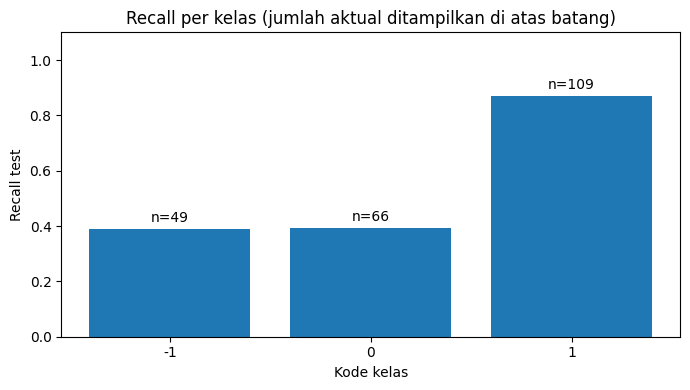

In [22]:
_, recall_per_class, _, support_per_class = precision_recall_fscore_support(
    y_test, pred_final, labels=[-1, 0, 1], zero_division=0
)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(['-1', '0', '1'], recall_per_class)
ax.set(xlabel='Kode kelas', ylabel='Recall test',
       title='Recall per kelas (jumlah aktual ditampilkan di atas batang)', ylim=(0, 1.1))
for i, (r, n) in enumerate(zip(recall_per_class, support_per_class)):
    ax.annotate(f'n={n}', (i, r), xytext=(0, 5),
                textcoords='offset points', ha='center')
fig.tight_layout()
plt.show()

## J. Analisis kesalahan model

Model klasifikasi tidak cukup dinilai dengan satu angka. Kita perlu menemukan **pasangan kelas yang sering tertukar** serta meninjau beberapa contoh salah prediksi. Namun, jangan mengubah keputusan model hanya karena melihat test: gunakan temuan ini sebagai hipotesis untuk pengumpulan data atau eksperimen berikutnya.

Teks dapat mengandung negasi, ironi, bahasa daerah, singkatan, emoji, atau konteks tertentu yang tidak ditangkap dengan baik oleh unigram/bigram.

In [23]:
analisis_test = pd.DataFrame({
    'Tweet': X_test.to_numpy(),
    'Aktual': y_test.to_numpy(),
    'Prediksi': pred_final,
})
analisis_test['Benar'] = analisis_test['Aktual'] == analisis_test['Prediksi']
print('Benar:', int(analisis_test['Benar'].sum()),
      '| Salah:', int((~analisis_test['Benar']).sum()))
print('Pasangan kelas yang keliru:')
display(pd.crosstab(
    analisis_test.loc[~analisis_test['Benar'], 'Aktual'],
    analisis_test.loc[~analisis_test['Benar'], 'Prediksi']
))
print('Contoh salah prediksi (maks. 8):')
display(analisis_test.loc[~analisis_test['Benar'], ['Tweet','Aktual','Prediksi']].head(8))

Benar: 140 | Salah: 84
Pasangan kelas yang keliru:


Prediksi,-1,0,1
Aktual,,,
-1,0,9,21
0,6,0,34
1,7,7,0


Contoh salah prediksi (maks. 8):


,Tweet,Aktual,Prediksi
1,Saya do'akan kita semua sehat wal afiat dan mu...,-1,1
2,Covid i oleh renang ra to,-1,1
3,Yah orang seperti anda ini yg kalau dimutasi m...,0,1
5,Pandemi corona mengancam nasib media lokal,-1,0
9,3.315 Pekerja di Jatim Jadi Korban PHK Karena ...,0,1
11,"Pemulung yg bawa karung putih ga dipedulikan, ...",1,-1
12,Harusnya hari ini aku ke jogja ngajak ibu jala...,0,1
13,salam dari jakarta iya mas. baiklah mas. stay ...,1,0


## K. Interpretasi fitur terkait kelas

Naive Bayes memiliki `feature_log_prob_`: perkiraan log probabilitas fitur bersyarat pada kelas. Kita dapat meninjau kata yang **relatif lebih berasosiasi** dengan suatu kelas daripada kelas lain dalam model hasil training.

Ini **bukan** penjelasan kausal atau bukti bahwa satu kata selalu menunjukkan sentimen tertentu. Nilai fitur dipengaruhi vocabulary, `max_features`, smoothing, konteks data, dan tokenisasi. Pada kalimat bernada negasi, konteks dapat terbalik walau kata yang sama muncul.

In [24]:
tf = model_final.named_steps['tfidf']
nb_model = model_final.named_steps['model']
fitur = tf.get_feature_names_out()
logp = nb_model.feature_log_prob_
rows = []
for i, kelas in enumerate(nb_model.classes_):
    pembanding = np.max(np.delete(logp, i, axis=0), axis=0)
    keunggulan_rel = logp[i] - pembanding
    top_indices = np.argsort(keunggulan_rel)[-12:][::-1]
    rows.extend([{'Kelas': int(kelas), 'Term': fitur[j],
                  'Selisih_logP': keunggulan_rel[j]}
                 for j in top_indices])
term_per_kelas = pd.DataFrame(rows)
print('Jumlah fitur dalam model final:', len(fitur))
display(term_per_kelas.round(3))

Jumlah fitur dalam model final: 1486


,Kelas,Term,Selisih_logP
0,-1,mati,1.584
1,-1,gua,1.402
2,-1,tau,1.305
3,-1,ne,1.259
4,-1,mandi,1.239
5,-1,krakatau,1.228
6,-1,indigo,1.217
7,-1,punya,1.211
8,-1,mampus,1.190
9,-1,kontol,1.185


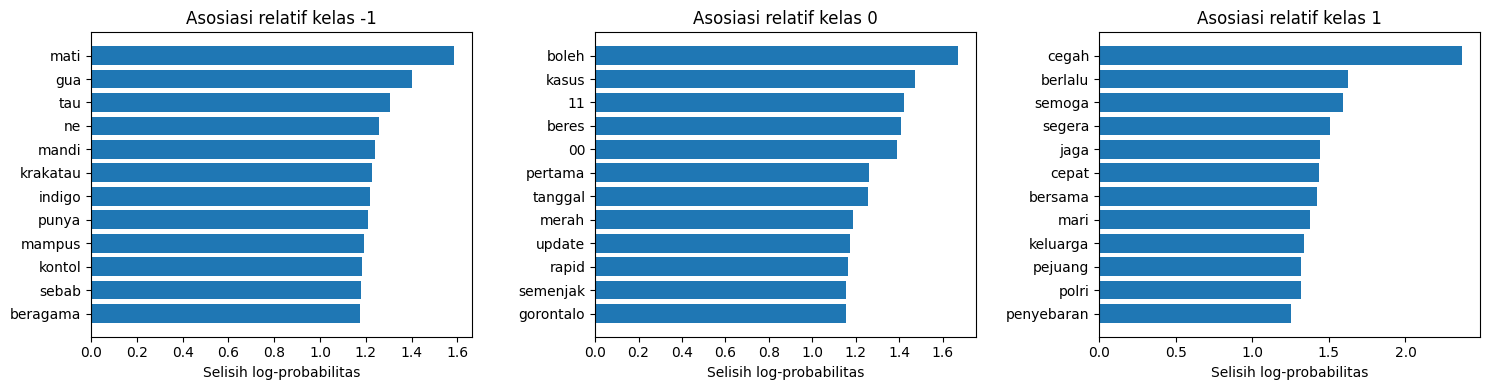

In [25]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, kelas in zip(axs, nb_model.classes_):
    bagian = term_per_kelas.loc[term_per_kelas['Kelas'] == kelas].iloc[::-1]
    ax.barh(bagian['Term'], bagian['Selisih_logP'])
    ax.set(title=f'Asosiasi relatif kelas {kelas}', xlabel='Selisih log-probabilitas')
fig.tight_layout()
plt.show()

## L. Inferensi: memprediksi teks yang belum diketahui labelnya

Gunakan satu pipeline yang telah di-fit: `model_final.predict(kalimat_baru)`. Tahap TF-IDF otomatis dijalankan di dalam Pipeline. `predict_proba` adalah **skor probabilitas menurut model**, tidak boleh langsung dianggap keyakinan yang terkalibrasi secara empiris.

**Batas domain:** korpus sumber berisi banyak pembicaraan terkait pandemi; contoh layanan, produk, atau bahasa baru mungkin memiliki pola berbeda (*domain shift*). Kalimat kosong dan masukan non-teks harus divalidasi sebelum prediksi.

In [26]:
kalimat_baru = [
    'Semoga semua segera membaik dan tetap sehat',
    'Kondisi ini membuat saya kecewa dan khawatir',
    'Pembaruan informasi untuk masyarakat hari ini'
]
pred_baru = model_final.predict(kalimat_baru)
proba_baru = model_final.predict_proba(kalimat_baru)
tabel_baru = pd.DataFrame({'Teks': kalimat_baru, 'Kode prediksi': pred_baru})
for j, kelas in enumerate(model_final.classes_):
    tabel_baru[f'Skor kelas {kelas}'] = proba_baru[:, j]
display(tabel_baru.round(3))

,Teks,Kode prediksi,Skor kelas -1,Skor kelas 0,Skor kelas 1
0,Semoga semua segera membaik dan tetap sehat,1,0.034,0.032,0.934
1,Kondisi ini membuat saya kecewa dan khawatir,1,0.137,0.336,0.528
2,Pembaruan informasi untuk masyarakat hari ini,1,0.064,0.198,0.738


In [27]:
def prediksi_teks_aman(texts, model):
    if not isinstance(texts, (list, tuple)) or len(texts) == 0:
        raise ValueError('Masukan harus list/tuple berisi minimal satu string.')
    if any(not isinstance(t, str) or not t.strip() for t in texts):
        raise ValueError('Setiap item harus berupa teks string yang tidak kosong.')
    tfidf_model = model.named_steps['tfidf']
    fitur_baru = tfidf_model.transform(texts)
    if any(fitur_baru[i].nnz == 0 for i in range(len(texts))):
        raise ValueError('Ada dokumen tanpa term yang dikenal vocabulary model (semuanya OOV).')
    return model.predict(texts)

print('Hasil input valid:', prediksi_teks_aman(kalimat_baru, model_final))
for tidak_valid in [['  '], ['zzzztokenunikqqq'], [None]]:
    try:
        print('Uji:', tidak_valid, '→', prediksi_teks_aman(tidak_valid, model_final))
    except ValueError as e:
        print('Masukan ditolak:', repr(tidak_valid), '| alasan:', e)

Hasil input valid: [1 1 1]
Masukan ditolak: ['  '] | alasan: Setiap item harus berupa teks string yang tidak kosong.
Masukan ditolak: ['zzzztokenunikqqq'] | alasan: Ada dokumen tanpa term yang dikenal vocabulary model (semuanya OOV).
Masukan ditolak: [None] | alasan: Setiap item harus berupa teks string yang tidak kosong.


### L1. Demonstrasi keterbatasan negasi

Kita menguji beberapa kalimat ilustratif yang berbeda hanya pada kata negasi. **Jangan** menyimpulkan model pasti memahami negasi hanya karena satu contoh tampak benar: TF-IDF unigrams/bigrams tidak memiliki pemahaman bahasa penuh dan label dari teks sintetis belum diverifikasi.

In [28]:
contoh_negasi = [
    'Situasi ini baik',
    'Situasi ini tidak baik',
    'Keputusan ini mengecewakan',
    'Keputusan ini tidak mengecewakan'
]
display(pd.DataFrame({
    'Teks ilustratif': contoh_negasi,
    'Kode prediksi': model_final.predict(contoh_negasi),
    'Skor tertinggi': model_final.predict_proba(contoh_negasi).max(axis=1)
}).round(3))

,Teks ilustratif,Kode prediksi,Skor tertinggi
0,Situasi ini baik,1,0.536
1,Situasi ini tidak baik,1,0.611
2,Keputusan ini mengecewakan,1,0.479
3,Keputusan ini tidak mengecewakan,1,0.567


## M. Menyimpan dan memuat pipeline sebagai artefak praktikum

Penyimpanan berikut hanya untuk **latihan reproducibility**. File model `.joblib` dapat menjalankan kode Python ketika dimuat: **jangan memuat artefak dari sumber tidak tepercaya**. Praktikum 07 membahas penyimpanan model dan tata kelola artefak secara lebih mendalam.

Artefak yang dihasilkan:

- `model_tfidf_naive_bayes.joblib`: pipeline TF-IDF + MultinomialNB.
- `evaluasi_model_teks.csv`: tabel metrik tiga pendekatan.
- `prediksi_test_teks.csv`: actual, prediction, benar/salah, dan teks test.
- `model_teks_info.json`: ringkasan parameter dan skema output.

In [29]:
import joblib

model_path = HASIL / 'model_tfidf_naive_bayes.joblib'
joblib.dump(model_final, model_path)
tabel_metrik.to_csv(HASIL / 'evaluasi_model_teks.csv', index=False)
analisis_test.to_csv(HASIL / 'prediksi_test_teks.csv', index=False, encoding='utf-8-sig')
metadata = {
    'nama_model': 'TF-IDF + Multinomial Naive Bayes',
    'sumber_dataset': 'Dataset_Sentimen_Emosi.csv',
    'fitur_input': 'Tweet (string)',
    'target': 'Sentimen (-1, 0, 1)',
    'jumlah_train': int(len(X_train)),
    'jumlah_test': int(len(X_test)),
    'label_kelas': [int(v) for v in model_final.classes_],
    'hiperparameter_cv': {k: str(v) for k, v in search.best_params_.items()},
    'macro_f1_cv': float(search.best_score_),
    'macro_f1_test': float(f1_score(y_test, pred_final, average='macro')),
    'catatan': 'Model edukasi; domain terbatas; bukan sistem penilaian individu.'
}
(HASIL / 'model_teks_info.json').write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False), encoding='utf-8'
)
loaded = joblib.load(model_path)
assert np.array_equal(loaded.predict(X_test), pred_final)
print('Artefak disimpan di:', HASIL)
for file in sorted(HASIL.glob('*')):
    print('-', file.name, file.stat().st_size, 'bytes')

Artefak disimpan di: /Users/masaboe/Documents/NGAJAR/ngudiWaluyo2026/final_release/Workshop_From_Data_to_ML/praktikum/hasil
- evaluasi_model_teks.csv 317 bytes
- konfigurasi_cv.csv 112 bytes
- model_teks_info.json 539 bytes
- model_tfidf_naive_bayes.joblib 126313 bytes
- modul04 160 bytes
- prediksi_test_teks.csv 33618 bytes


## N. Ringkasan dan checklist interpretasi

Periksa output aktual dari notebook ini lalu jawab:

- Berapa baris semula, berapa setelah pembersihan, dan bagaimana distribusi tiga kelas?
- Berapa dimensi matriks TF-IDF train? Berapa term nonnol pada satu dokumen?
- Apakah baseline sebagian besar memprediksi satu kelas? Mengapa macro-F1 penting?
- Hiperparameter apa yang dipilih oleh cross-validation, **tanpa mengintip test**?
- Kelas mana yang paling sulit dikenali menurut per-class recall dan confusion matrix?
- Mengapa beberapa kata teratas tidak selalu menjelaskan sentimen secara pasti?
- Apakah hasil dari tweet terkait pandemi layak ditransfer langsung ke ulasan produk?

**Penting:** Bandingkan nilai dari eksekusi Anda; hasil numerik dapat berubah bila dataset, versi library, atau parameter diubah.

### N1. Format laporan eksperimen yang disarankan

Untuk melatih pelaporan akademik yang dapat direproduksi, laporan mahasiswa sebaiknya menjelaskan **metode** sebelum mencantumkan hasil: dataset & jumlah akhir, definisi label yang tersedia, aturan pembersihan, train/test split, strategi CV, ruang hiperparameter, metrik utama, tabel hasil, dan kelemahan. Jika ada hipotesis baru yang muncul setelah melihat holdout, tuliskan sebagai **riset lanjutan**, bukan diam-diam mengulang optimasi di test yang sama.

## O. Latihan pemahaman — 12 soal

Kerjakan terlebih dahulu **tanpa membuka kunci jawaban** di Bagian R.

**S1.** Jelaskan perbedaan input text `Tweet`, label `Sentimen`, dan anotasi `Emosi`.

**S2.** Mengapa teks identik berlabel berbeda harus diaudit sebelum training?

**S3.** Mengapa deduplikasi dilakukan sebelum train–test split?

**S4.** Jelaskan arti matriks TF-IDF berukuran `(n_train, p)`.

**S5.** Apa perbedaan `fit_transform()` dan `transform()` pada TF-IDF dalam evaluasi?

**S6.** Apa pengaruh unigram vs bigram terhadap vocabulary dan pola kalimat yang dapat dipelajari?

**S7.** Jelaskan asumsi dasar Multinomial Naive Bayes dan peran `alpha`.

**S8.** Mengapa `Pipeline` membantu mengurangi data leakage pada cross-validation?

**S9.** Mengapa accuracy saja kurang memadai ketika jumlah kelas tidak seimbang?

**S10.** Jelaskan perbedaan macro-F1 dan weighted-F1.

**S11.** Mengapa memeriksa test berulang kali untuk memilih model dianggap keliru?

**S12.** Sebutkan tiga alasan prediksi pada domain baru bisa kurang andal.

## P. Latihan kode — 10 tugas

Kerjakan menggunakan variabel yang sudah dibuat di bagian utama. **Kunci jawaban dan contoh kode executable** ada di Bagian R.

**P1.** Tampilkan tabel jumlah dan proporsi setiap label pada `clean`.

**P2.** Hitung median panjang karakter `Tweet` per kelas sentimen.

**P3.** Perlihatkan empat record pertama dari `X_train` dengan labelnya tanpa mengubah indeks asli.

**P4.** Tampilkan 10 term TF-IDF teratas untuk dokumen ke-2 di training.

**P5.** Hitung persentase elemen nonnol pada matriks `Xt_train` (*density*).

**P6.** Bandingkan macro-F1 CV dari Naive Bayes dengan `alpha=0.5` versus `alpha=2.0`, `ngram_range=(1,1)`.

**P7.** Hitung precision, recall, F1 setiap kelas pada holdout test dari `model_final`.

**P8.** Cari kode kelas dengan recall test terendah dan tuliskan jumlah support-nya.

**P9.** Buat tabel 5 teks baru berikut kode prediksi dan nilai skor maksimum menurut model (tanpa menganggap skor terkalibrasi).

**P10.** Simpan ringkasan konfigurasi pilihan CV ke CSV `konfigurasi_cv.csv` di folder `HASIL`.

## Q. Tantangan terapan — 3 studi kasus

**T1 — Kebocoran vocabulary.** Mahasiswa melakukan `TfidfVectorizer().fit_transform(X)` **sebelum** train/test split. Identifikasi sumber masalahnya dan tulis alur pembetulannya.

**T2 — Label tidak selaras.** Anda menemukan dua baris tweet yang benar-benar sama tetapi label sentimennya berbeda. Apakah aman memilih label mayoritas untuk dua baris tersebut? Jelaskan keputusan audit yang dapat dipertanggungjawabkan.

**T3 — Evaluasi berlebihan.** Model mendapat accuracy test yang cukup tinggi tetapi macro-F1 rendah. Jelaskan kemungkinan penyebab dan dua perbaikan rancangan eksperimen tanpa mengubah hasil test secara oportunistis.

## R. Kunci jawaban dan pembahasan

**Catatan untuk dosen:** Bagian ini sengaja ditempatkan **setelah** semua latihan. Mahasiswa dapat mencoba terlebih dahulu, lalu menjalankan sel jawaban untuk memverifikasi. Solusi berikut hanya memakai **training untuk fitting/pemilihan parameter**; test dipakai untuk melaporkan evaluasi akhir.

### R1. Jawaban konsep S1–S6

- **S1:** `Tweet` adalah fitur teks; `Sentimen` target; `Emosi` target anotasi lain yang tidak menjadi masukan model teks.
- **S2:** Jika satu teks identik memiliki label berbeda, ground truth ambigu; perlu audit aturan anotasi sebelum mempelajari hubungan fitur–kelas.
- **S3:** Duplikat lintas train/test dapat meningkatkan skor semu karena teks uji pernah dilihat saat training.
- **S4:** `n_train` baris mewakili dokumen training, `p` kolom mewakili term vocabulary; nilai adalah bobot fitur.
- **S5:** `fit_transform` mempelajari vocabulary/IDF lalu mentransformasi training; `transform` menerapkan vocabulary/IDF yang sudah dipelajari pada validasi/test.
- **S6:** Bigram menangkap pasangan kata berurutan, dapat membantu konteks, tetapi memperbesar ruang kandidat fitur dan membuat fitur lebih jarang muncul.

### R2. Jawaban konsep S7–S12

- **S7:** MultinomialNB memakai penyederhanaan independensi fitur bersyarat pada kelas; `alpha` memberi smoothing. TF-IDF dipakai sebagai bobot nonnegatif, bukan hitungan integer sebenarnya.
- **S8:** Vectorizer dalam pipeline hanya di-fit pada bagian training tiap fold dan ditransform ke fold validasi tanpa melihat isi fold tersebut saat fitting.
- **S9:** Accuracy dapat tinggi jika model dominan menebak kelas yang paling sering, sementara kelas minoritas jarang dikenali.
- **S10:** Macro-F1 adalah rerata F1 antar kelas berbobot sama; weighted-F1 berbobot jumlah sampel aktual tiap kelas.
- **S11:** Pemilihan model berdasarkan test menjadikan test bagian dari optimasi; skor test akhirnya tidak independen.
- **S12:** Pergeseran topik/domain, slang/bahasa berbeda, serta perubahan definisi anotasi dan distribusi kelas bisa mengurangi keandalan.

### R3. Solusi kode P1–P2 — komposisi dan panjang teks

In [30]:
# Jawaban P1
jumlah = clean['Sentimen'].value_counts().sort_index()
proporsi = clean['Sentimen'].value_counts(normalize=True).sort_index()
display(pd.DataFrame({'Jumlah': jumlah, 'Proporsi': proporsi}).round(3))

# Jawaban P2
median_per_kelas = clean.assign(
    n_karakter=clean['Tweet'].str.len()
).groupby('Sentimen')['n_karakter'].median()
display(median_per_kelas.to_frame('median_karakter'))

,Jumlah,Proporsi
Sentimen,,
-1,194,0.217
0,266,0.297
1,436,0.487


,median_karakter
Sentimen,
-1,102.5
0,102.0
1,132.5


### R4. Solusi kode P3–P4 — record training dan top term

In [31]:
# Jawaban P3: indeks dipertahankan untuk menjaga pasangan X/y
head_train = pd.DataFrame({'Tweet': X_train.head(4), 'Sentimen': y_train.head(4)})
display(head_train)

# Jawaban P4: dokumen ke-2 berarti posisi iloc[1], bukan indeks label 2
idx_doc = 1
bobot_doc = pd.DataFrame({
    'Term': feature_names,
    'TF-IDF': Xt_train[idx_doc].toarray().ravel()
})
display(bobot_doc.loc[bobot_doc['TF-IDF'] > 0].nlargest(10, 'TF-IDF'))

,Tweet,Sentimen
202,Ada 15 cra mnyurh Covid-19 sgr prg 5.Jngn lgi ...,1
687,"Kasus Covid-19 di Indonesia Bertambah 330, Tot...",0
259,Semoga indonesia mampu menekan lonjakan pasien...,1
831,Operasi Nyahkuman Di Sekitar Pekan Simunjan Ce...,1


,Term,TF-IDF
33,842,0.446489
1833,total,0.426460
27,330,0.410925
217,bertambah,0.378203
622,kasus,0.349974
1112,orang,0.279545
517,indonesia,0.261117
322,di,0.156943
14,19,0.090587
286,covid,0.072364


### R5. Solusi kode P5–P6 — sparsity dan CV alpha

In [32]:
# Jawaban P5
jumlah_sel = Xt_train.shape[0] * Xt_train.shape[1]
density_pct = Xt_train.nnz / jumlah_sel * 100
print(f'Density = {density_pct:.3f}% | Sparsity = {100 - density_pct:.3f}%')

# Jawaban P6: evaluasi cross-validation hanya pada train
hasil_alpha = []
for alpha in [0.5, 2.0]:
    percobaan = Pipeline([
        ('tfidf', TfidfVectorizer(max_features=2000, ngram_range=(1, 1))),
        ('model', MultinomialNB(alpha=alpha))
    ])
    score = cross_val_score(percobaan, X_train, y_train,
                            cv=cv, scoring='f1_macro')
    hasil_alpha.append({'alpha': alpha, 'macro_F1_CV': score.mean(), 'std_CV': score.std()})
display(pd.DataFrame(hasil_alpha).round(4))

Density = 0.777% | Sparsity = 99.223%


,alpha,macro_F1_CV,std_CV
0,0.5,0.4441,0.0263
1,2.0,0.2756,0.0243


### R6. Solusi kode P7–P8 — diagnostik per kelas

In [33]:
# Jawaban P7
prec, rec, f1, supp = precision_recall_fscore_support(
    y_test, pred_final, labels=[-1, 0, 1], zero_division=0
)
diagnostik = pd.DataFrame({
    'Kelas': [-1, 0, 1], 'Precision': prec, 'Recall': rec, 'F1': f1, 'Support': supp
})
display(diagnostik.round(3))

# Jawaban P8
sulit = diagnostik.loc[diagnostik['Recall'].idxmin()]
print('Recall terendah pada kelas:', int(sulit['Kelas']))
print('Recall:', round(float(sulit['Recall']), 3), '| Support:', int(sulit['Support']))

,Kelas,Precision,Recall,F1,Support
0,-1,0.594,0.388,0.469,49
1,0,0.619,0.394,0.481,66
2,1,0.633,0.872,0.734,109


Recall terendah pada kelas: -1
Recall: 0.388 | Support: 49


### R7. Solusi kode P9–P10 — prediksi dan ekspor konfigurasi

In [34]:
# Jawaban P9
teks_latihan = [
    'Tetap jaga kesehatan dan keselamatan bersama',
    'Saya tidak setuju dengan keadaan ini',
    'Informasi terbaru telah tersedia',
    'Semoga kebijakan itu membawa perubahan baik',
    'Saya benar-benar khawatir dengan situasi ini'
]
yhat_latihan = model_final.predict(teks_latihan)
skor_latihan = model_final.predict_proba(teks_latihan).max(axis=1)
display(pd.DataFrame({
    'Teks': teks_latihan, 'Prediksi': yhat_latihan,
    'Skor_maksimum_model': skor_latihan
}).round(3))

# Jawaban P10
konfigurasi_cv = pd.DataFrame([{
    **{k: str(v) for k, v in search.best_params_.items()},
    'macro_F1_cv': float(search.best_score_),
    'jumlah_kombinasi': len(search.cv_results_['params'])
}])
konfigurasi_cv.to_csv(HASIL / 'konfigurasi_cv.csv', index=False)
display(konfigurasi_cv)

,Teks,Prediksi,Skor_maksimum_model
0,Tetap jaga kesehatan dan keselamatan bersama,1,0.941
1,Saya tidak setuju dengan keadaan ini,1,0.647
2,Informasi terbaru telah tersedia,0,0.468
3,Semoga kebijakan itu membawa perubahan baik,1,0.817
4,Saya benar-benar khawatir dengan situasi ini,1,0.377


,model__alpha,tfidf__min_df,tfidf__ngram_range,macro_F1_cv,jumlah_kombinasi
0,0.5,2,"(1, 1)",0.490689,12


### R8. Pembahasan studi kasus T1–T3

**T1 — Kebocoran vocabulary:** salah karena pemilihan vocabulary/IDF sudah melihat test. Perbaikan: deduplikasi → split → `Pipeline([('tfidf', TfidfVectorizer()), ('model', MultinomialNB())])` → train/CV untuk fit; evaluasi hanya sekali pada holdout.

**T2 — Label tidak selaras:** memilih mayoritas begitu saja tidak dibenarkan karena dua anotasi tidak cukup memberi bukti bahwa satu label lebih benar. Audit sumber, dokumentasi aturan, adjudikasi anotator bila tersedia; untuk praktikum ini kita mengecualikan teks konflik secara transparan.

**T3 — Accuracy tinggi, macro-F1 rendah:** bisa muncul jika kelas dominan sering benar tetapi kelas minoritas banyak gagal. Perbaikan: analisis label, tambah contoh yang representatif, uji validasi terstratifikasi dan bandingkan pendekatan fitur/algoritma **hanya pada train**; pertahankan test untuk audit independen.

## S. Evaluasi akhir dan transisi pembelajaran

Mahasiswa dinyatakan menguasai inti modul apabila dapat:

- [ ] Menjelaskan tiga peran kolom sumber dan dua masalah kualitas teks (duplikat dan konflik label).
- [ ] Membuktikan data test tidak dipakai ketika mempelajari vocabulary atau memilih hyperparameter.
- [ ] Menampilkan matriks TF-IDF dan top term untuk satu dokumen training.
- [ ] Membangun pipeline TF-IDF + MultinomialNB dan membandingkan dengan baseline.
- [ ] Menginterpretasikan macro-F1, confusion matrix, kesalahan antar kelas, dan keterbatasan domain.
- [ ] Menguji teks baru dengan validasi input dan menghasilkan artefak model yang dapat di-load ulang.

**Tugas laporan singkat (1–2 halaman):** tujuan & definisi label, ringkasan cleaning dan jumlah sampel, protokol split, tabel CV/test, confusion matrix, tiga contoh kesalahan, analisis domain shift, dan simpulan terbatas pada dataset.

**Hubungan dengan modul lain:** Praktikum 02 menjelaskan bagaimana teks direpresentasikan; Praktikum 03 memperkenalkan pola preprocessing yang aman; Praktikum 04 menanamkan baseline dan holdout; Praktikum 09 menggabungkan kompetensi tersebut menjadi klasifikasi teks yang dapat diuji. Jangan menganggap nilai test sebagai jaminan performa pada data dunia nyata.